# V-to-I converter (Fig. 16)

Two OTA-driven NMOS source followers, two I_REF sinks and R between ideal input sources and ideal ammeters that hold the regulated nodes at V_ref2. Currents are referred back to the input as (I_out+ − I_out−) · R / 2, so INL and THD are in input LSBs of V_FS / 2^N.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sarlib import specs as S
from sarlib.analysis import load_real, load_complex, parse_op_log, eng, window_around, settle_time, Report

DATA = Path('simulation/vi_converter.sch')
v = S.vi
SP = v.SPECS
I_FS = S.I_FS_MEAS
LSB_V = v.V_FS / S.NCODE
LSB_I = I_FS / S.NCODE
rep = Report()

## Operating points

Mid scale and both ends of the driven range.

In [2]:
MODEL = {'n': 'nfet_01v8', 'p': 'pfet_01v8', 'plvt': 'pfet_01v8_lvt'}
DEVICES = {'T1': ('xm1', 'n'), 'T2': ('xm2', 'n'), 'sink 1': ('xm3', 'n'), 'sink 2': ('xm4', 'n'), 'sink ref': ('xm5', 'n')}
for k, x in ((1, 'x1'), (2, 'x2')):
    for name, dev, ty in (('tail', 'xm11', 'p'), ('pair+', 'xm1', 'plvt'), ('pair-', 'xm2', 'plvt'), ('fold sink d', 'xm5', 'n'),
                          ('fold sink o', 'xm6', 'n'), ('n casc d', 'xm3', 'n'), ('n casc o', 'xm4', 'n'), ('p casc d', 'xm7', 'p'),
                          ('p casc o', 'xm8', 'p'), ('mirror d', 'xm9', 'p'), ('mirror o', 'xm10', 'p')):
        DEVICES[f'OTA{k} {name}'] = (f'{x}.{dev}', ty)

nodes, marg = {}, {}
for case in ('mid', 'lo', 'hi'):
    vals = parse_op_log(DATA / f'op_{case}.log')
    nodes[case] = {k: vals[k] for k in ('v(inp)', 'v(inn)', 'v(s1)', 'v(s2)', 'v(g1)', 'v(g2)')}
    nodes[case].update({'io1 (uA)': 1e6 * vals['io1'], 'io2 (uA)': 1e6 * vals['io2'], 'idd (uA)': 1e6 * vals['idd'],
                        'follow err (mV)': 1e3 * max(abs(vals['v(s1)'] - vals['v(inp)']), abs(vals['v(s2)'] - vals['v(inn)']))})
    pre = lambda p, ty: f'@m.{p}.msky130_fd_pr__{MODEL[ty]}'
    marg[case] = {d: abs(vals[f'{pre(p, ty)}[vds]']) - abs(vals[f'{pre(p, ty)}[vdsat]']) for d, (p, ty) in DEVICES.items()}
NODES, MARG = pd.DataFrame(nodes), pd.DataFrame(marg)
rep.limit('source node follows the input', NODES.loc['follow err (mV)'].max(), '{:.2f} mV', SP['follow_mv_max'], '<=', 'mV')
rep.limit('every device saturated, worst VDS - VDSAT', MARG.min().min(), '{:.3f} V', S.VDS_MARGIN, '>=', 'V')
rep.info('supply current at mid scale', f"{NODES.loc['idd (uA)', 'mid']:.1f} uA")
display(NODES.round(4))
MARG.round(3)

,mid,lo,hi
v(inp),0.4500,0.3177,0.5823
v(inn),0.4500,0.5823,0.3177
v(s1),0.4494,0.3174,0.5814
v(s2),0.4494,0.5814,0.3174
v(g1),1.2258,0.9650,1.4275
v(g2),1.2258,1.4275,0.9650
io1 (uA),9.9190,1.4753,18.3511
io2 (uA),9.9190,18.3511,1.4753
idd (uA),59.0118,59.0081,59.0081
follow err (mV),0.5781,0.8995,0.8995


,mid,lo,hi
T1,0.985,1.171,0.819
T2,0.985,0.819,1.171
sink 1,0.321,0.188,0.453
sink 2,0.321,0.453,0.188
sink ref,0.530,0.530,0.530
OTA1 tail,0.501,0.612,0.390
OTA1 pair+,0.867,0.756,0.978
OTA1 pair-,0.864,0.754,0.974
OTA1 fold sink d,0.031,0.031,0.031
OTA1 fold sink o,0.034,0.033,0.035


## Static transfer

Endpoint INL over the driven range |V+ − V−| ≤ VD_PEAK.

gain error +0.357 %; both outputs above 1 % of I_FS for -304 ... 304 mV


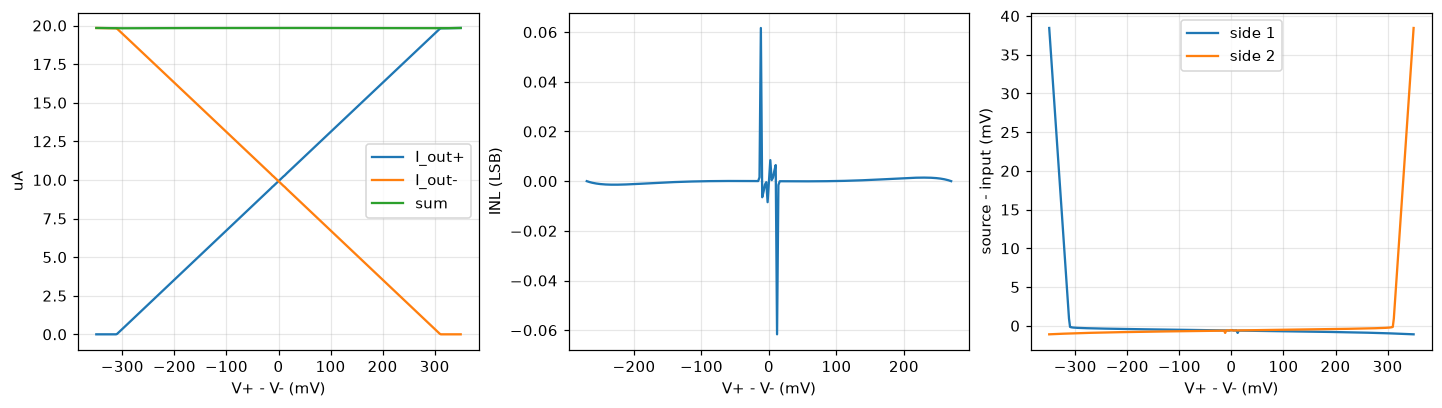

In [3]:
x, (io1, io2, vs1, vs2, vg1, vg2, vinp, vinn, idd) = load_real(DATA / 'dc_sweep.csv')
vd = vinp - vinn
xeq = (io1 - io2) * v.R_OHM / 2
um = np.abs(vd) <= (1 - v.EDGE_SKIP) * v.V_FS / 2 + 1e-9
i0, i1 = np.argmin(vd[um]), np.argmax(vd[um])
line = xeq[um][i0] + (xeq[um][i1] - xeq[um][i0]) * (vd[um] - vd[um][i0]) / (vd[um][i1] - vd[um][i0])
err = xeq[um] - line
inl = np.abs(err).max() / LSB_V
gain = np.polyfit(vd[um], xeq[um], 1)[0]
zero = float(np.interp(0.0, vd, xeq)) / LSB_V
sum_err = np.abs(io1 + io2 - I_FS)[um].max() / LSB_I
alive = (io1 > 0.01 * I_FS) & (io2 > 0.01 * I_FS)
vd_lo, vd_hi = vd[alive].min(), vd[alive].max()
print(f'gain error {100 * (gain - 1):+.3f} %; both outputs above 1 % of I_FS for {1e3 * vd_lo:.0f} ... {1e3 * vd_hi:.0f} mV')
rep.limit('INL (input referred)', inl, '{:.3f} LSB', SP['inl_lsb_max'], '<=', 'LSB')
rep.limit('zero error', abs(zero), '{:.2f} LSB', SP['offset_lsb_max'], '<=', 'LSB')
rep.info('gain error', f'{100 * (gain - 1):+.3f} %')
rep.limit('I_out+ + I_out- = I_FS', sum_err, '{:.3f} LSB', SP['sum_err_lsb_max'], '<=', 'LSB')
rep.check('both outputs alive over the driven range', f'{1e3 * vd_lo:.0f} ... {1e3 * vd_hi:.0f} mV', f'covers +/- {1e3 * v.VD_PEAK:.0f} mV',
          vd_lo <= -v.VD_PEAK and vd_hi >= v.VD_PEAK)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].plot(1e3 * vd, 1e6 * io1, label='I_out+'); axs[0].plot(1e3 * vd, 1e6 * io2, label='I_out-'); axs[0].plot(1e3 * vd, 1e6 * (io1 + io2), label='sum')
axs[0].set(xlabel='V+ - V- (mV)', ylabel='uA'); axs[0].legend()
axs[1].plot(1e3 * vd[um], err / LSB_V); axs[1].set(xlabel='V+ - V- (mV)', ylabel='INL (LSB)')
axs[2].plot(1e3 * vd, 1e3 * (vs1 - vinp), label='side 1'); axs[2].plot(1e3 * vd, 1e3 * (vs2 - vinn), label='side 2')
axs[2].set(xlabel='V+ - V- (mV)', ylabel='source - input (mV)'); axs[2].legend()
plt.show()

## Common-mode sensitivity

Input common mode swept at three differential inputs; change of the per-side current I_R and of the sum over V_CM ± CM_TOL.

lo : vd = -243 mV, within 0.25 LSB for V_CM 0.33 - 0.56 V
mid: vd = +0 mV, within 0.25 LSB for V_CM 0.05 - 1.45 V
hi : vd = +243 mV, within 0.25 LSB for V_CM 0.33 - 0.56 V


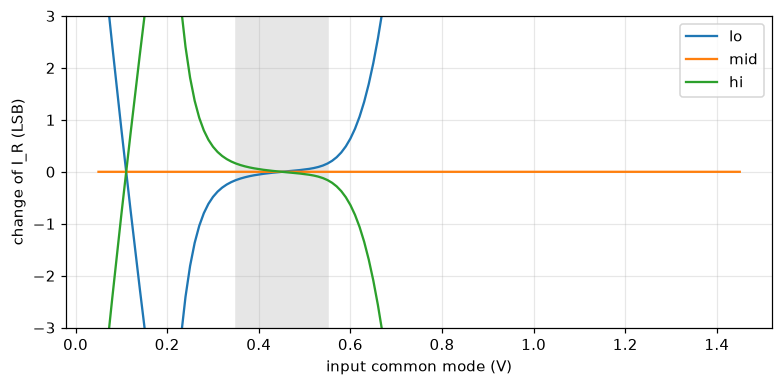

In [4]:
worst_d = worst_s = 0.0
fig, ax = plt.subplots(figsize=(7, 3.4))
for case in ('lo', 'mid', 'hi'):
    x, ys = load_real(DATA / f'cm_sweep_{case}.csv')
    idf, sm = (ys[0] - ys[1]) / 2, ys[0] + ys[1]
    dev_d = (idf - np.interp(v.VCM, x, idf)) / LSB_I
    dev_s = (sm - np.interp(v.VCM, x, sm)) / LSB_I
    m = (x >= v.VCM - v.CM_TOL) & (x <= v.VCM + v.CM_TOL)
    worst_d, worst_s = max(worst_d, np.abs(dev_d[m]).max()), max(worst_s, np.abs(dev_s[m]).max())
    w = window_around(x, np.abs(dev_d) <= SP['cm_lsb_max'], v.VCM)
    print(f"{case:3}: vd = {1e3 * np.interp(v.VCM, x, ys[6] - ys[7]):+.0f} mV, within {SP['cm_lsb_max']} LSB for V_CM {w[0]:.2f} - {w[1]:.2f} V")
    ax.plot(x, dev_d, label=case)
ax.axvspan(v.VCM - v.CM_TOL, v.VCM + v.CM_TOL, color='0.9'); ax.set(xlabel='input common mode (V)', ylabel='change of I_R (LSB)', ylim=(-3, 3)); ax.legend()
plt.show()
rep.limit('common-mode sensitivity of I_R', worst_d, '{:.3f} LSB', SP['cm_lsb_max'], '<=', 'LSB')
rep.limit('common-mode sensitivity of the sum', worst_s, '{:.3f} LSB', SP['sum_err_lsb_max'], '<=', 'LSB')

## Regulated-node window

In [5]:
x, (io1, io2, *_) = load_real(DATA / 'out_sweep.csv')
d1 = (io1 - np.interp(S.VREF2, x, io1)) / LSB_I
d2 = (io2 - np.interp(S.VREF2, x, io2)) / LSB_I
w = window_around(x, (np.abs(d1) <= 0.25) & (np.abs(d2) <= 0.25), S.VREF2)
near = (x >= S.VREF2 - 0.05) & (x <= S.VREF2 + 0.05)
print(f'output resistance near V_ref2 {eng(1 / abs(np.polyfit(x[near], io1[near], 1)[0]), "ohm")}')
rep.check('regulated-node window', f'{w[0]:.2f} - {w[1]:.2f} V', f'covers {S.VREF2 - v.VREF2_TOL:.2f} - {S.VREF2 + v.VREF2_TOL:.2f} V',
          w[0] <= S.VREF2 - v.VREF2_TOL and w[1] >= S.VREF2 + v.VREF2_TOL)

output resistance near V_ref2 8.19 Gohm


## Sine (THD) and step settling

THD -70.7 dBc, SFDR 71.0 dBc, fundamental 255.8 mV
settling per step (ns): 35.1, 39.5, 32.5


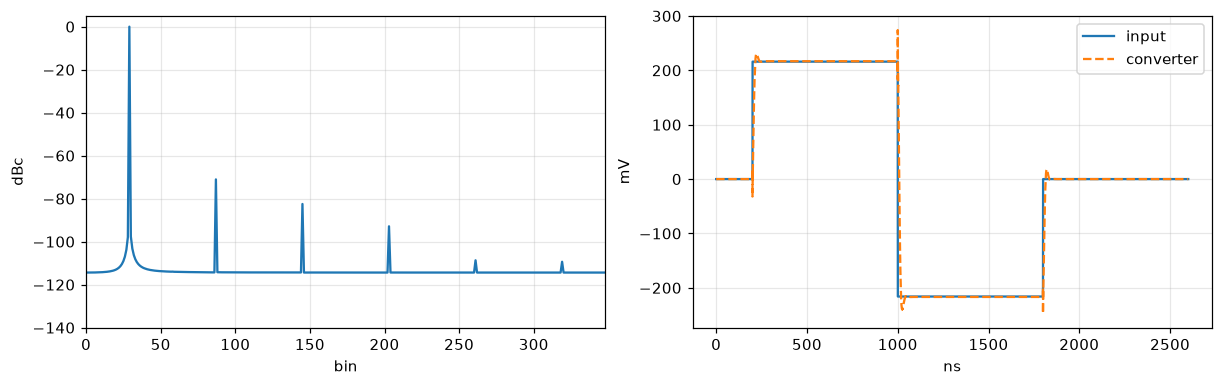

In [6]:
t, (vdiff, io1, io2) = load_real(DATA / 'tran_sine.csv')
tu = np.arange(v.N_FFT) * (v.T_WIN / v.N_FFT)
xo = np.interp(tu, t, io1 - io2) * v.R_OHM / 2
h = np.abs(np.fft.rfft(xo)) / v.N_FFT * 2
fund = h[v.M_PER]
bins = [(k * v.M_PER) % v.N_FFT for k in range(2, 11)]
harm = np.array([h[b if b <= v.N_FFT // 2 else v.N_FFT - b] for b in bins])
thd = 20 * np.log10(np.sqrt(np.sum(harm ** 2)) / fund)
mask = np.ones(len(h), bool); mask[:2] = False; mask[v.M_PER - 1:v.M_PER + 2] = False
print(f'THD {thd:.1f} dBc, SFDR {20 * np.log10(fund / h[mask].max()):.1f} dBc, fundamental {1e3 * fund:.1f} mV')
rep.limit('THD, -0.5 dBFS sine', thd, '{:.1f} dBc', SP['thd_db_max'], '<=', 'dBc')

t, (vdiff, io1, io2, vg1, vs1) = load_real(DATA / 'tran_step.csv')
xs = (io1 - io2) * v.R_OHM / 2
edges = list(v.STEP_TIMES) + [t[-1]]
settle = []
for k, t0 in enumerate(v.STEP_TIMES):
    seg = (t >= t0) & (t < edges[k + 1])
    tt, xx = t[seg], xs[seg]
    settle.append(1e9 * settle_time(tt, xx, xx[tt > tt[-1] - 0.1 * (tt[-1] - tt[0])].mean(), 0.5 * LSB_V, t0))
print('settling per step (ns): ' + ', '.join(f'{x:.1f}' for x in settle))
rep.limit('settling to 0.5 LSB after a large step', max(settle), '{:.1f} ns', SP['settle_ns_max'], '<=', 'ns')

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(20 * np.log10(np.maximum(h / fund, 1e-12))); axs[0].set(xlim=(0, 12 * v.M_PER), ylim=(-140, 5), xlabel='bin', ylabel='dBc')
axs[1].plot(1e9 * t, 1e3 * vdiff, label='input'); axs[1].plot(1e9 * t, 1e3 * xs, '--', label='converter')
axs[1].set(xlabel='ns', ylabel='mV'); axs[1].legend()
plt.show()

## Loop gain

T = −v(s1)/v(fb1) at mid scale and both range ends.

mid: 56.4 dB at 1 kHz, unity at 25.2 MHz, PM 61.0 deg
lo : 54.3 dB at 1 kHz, unity at 19.5 MHz, PM 64.6 deg
hi : 51.9 dB at 1 kHz, unity at 26.4 MHz, PM 61.1 deg


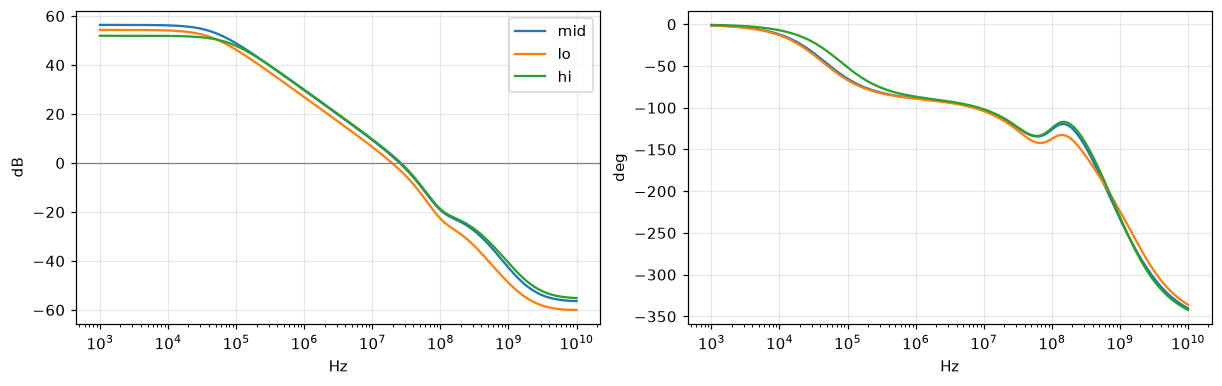

In [7]:
pms = {}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for case in ('mid', 'lo', 'hi'):
    f, lg = load_complex(DATA / f'ac_loop_{case}.csv')
    mag, ph = 20 * np.log10(np.abs(lg)), np.degrees(np.unwrap(np.angle(lg)))
    i = int(np.where((mag[:-1] > 0) & (mag[1:] <= 0))[0][0])
    fr = -mag[i] / (mag[i + 1] - mag[i])
    fu = np.exp(np.log(f[i]) + fr * (np.log(f[i + 1]) - np.log(f[i])))
    pms[case] = 180 + ph[i] + fr * (ph[i + 1] - ph[i])
    print(f'{case:3}: {mag[0]:.1f} dB at {eng(f[0], "Hz")}, unity at {eng(fu, "Hz")}, PM {pms[case]:.1f} deg')
    axs[0].semilogx(f, mag, label=case); axs[1].semilogx(f, ph, label=case)
axs[0].axhline(0, c='0.5', lw=0.8); axs[0].set(xlabel='Hz', ylabel='dB'); axs[0].legend(); axs[1].set(xlabel='Hz', ylabel='deg')
plt.show()
rep.limit('loop phase margin (worst case)', min(pms.values()), '{:.1f} deg', SP['pm_deg_min'], '>=', 'deg')

## Summary

In [8]:
rep.table()

,check,value,spec,result
0,source node follows the input,0.90 mV,<= 5 mV,PASS
1,"every device saturated, worst VDS - VDSAT",0.025 V,>= 0.05 V,FAIL
2,supply current at mid scale,59.0 uA,,INFO
3,INL (input referred),0.062 LSB,<= 0.25 LSB,PASS
4,zero error,0.00 LSB,<= 2 LSB,PASS
5,gain error,+0.357 %,,INFO
6,I_out+ + I_out- = I_FS,1.041 LSB,<= 0.5 LSB,FAIL
7,both outputs alive over the driven range,-304 ... 304 mV,covers +/- 270 mV,PASS
8,common-mode sensitivity of I_R,0.160 LSB,<= 0.25 LSB,PASS
9,common-mode sensitivity of the sum,0.801 LSB,<= 0.5 LSB,FAIL
